# Tome S3, Chapter 1: How conjectures are born and die (Python companion)

Exercises first, solutions at the end. We test a gallery of patterns until they break, compute the Liouville function up to $10^9$ to watch Pólya's conjecture die at Tanaka's number, find Lander and Parkin's fifth powers, and put the Borwein integrals and their probabilistic explanation side by side. We use `numpy`, `sympy`, `mpmath` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import sympy
import mpmath as mp
from fractions import Fraction
import matplotlib.pyplot as plt
rng = np.random.default_rng(1)

## Exercises

**P1.1 (★) A gallery of broken patterns.** Check that $n^2+n+41$ is prime for $0\le n\le 39$ (Exercise 1.1), that $641$ divides $2^{32}+1$ (Exercise 1.2), that $31, 331, \dots, 33333331$ are prime and $333333331$ is not (Exercise 1.3). Then find every odd composite $n<10^6$ that is not of the form $p+2a^2$.

**P1.2 (★★) Pólya's problem.** Compute $L(x)=\sum_{n\le x}\lambda(n)$ for all $x\le 10^9$ with a segmented sieve, and find the first $x\ge2$ with $L(x)>0$. Plot $L(x)/\sqrt x$ and compare its typical level with $1/\zeta(\tfrac12)$ (Exercise 1.10).

**P1.3 (★) Mertens.** In the same pass, compute $M(x)=\sum_{n\le x}\mu(n)$ and the extreme values of $M(x)/\sqrt x$ for $10^3\le x\le 10^9$. How far are they from $\pm1$?

**P1.4 (★★) Euler's sum of powers.** Find all solutions of $a^5+b^5+c^5+d^5=e^5$ with $0<a\le b\le c\le d<e<150$, by a meet-in-the-middle search. Check the identities of Elkies and Frye for fourth powers.

**P1.5 (★★) The Borwein integrals.** Compute $\int_0^\infty \prod_{k=0}^{n}\operatorname{sinc}\frac{x}{2k+1}\,dx$ numerically for $n=0,\dots,7$. Compare the deficit for $n=7$ with Corollary 1.5, and estimate $\mathbb P(|S|<1)$ of Theorem 1.4 by Monte Carlo for $a_k=\frac1{k+1}$ (Exercise 1.12).

## Solutions

### P1.1
**How to find it.** For Goldbach's other conjecture, sieve the primes, mark every $p+2a^2$, and list the odd composites left unmarked.

In [2]:
print('n^2+n+41 composite for n <= 45 at', [n for n in range(46) if not sympy.isprime(n*n + n + 41)])
print('2^32 + 1 mod 641 =', (2**32 + 1) % 641)
for k in range(1, 10):
    N = (10**(k + 1) - 7) // 3
    print(N, sympy.factorint(N))
M = 10**6
isp = np.ones(M, bool); isp[:2] = False
for p in range(2, int(M**0.5) + 1):
    if isp[p]: isp[p*p::p] = False
rep = np.zeros(M, bool)
primes = np.nonzero(isp)[0]
for a in range(0, int((M / 2)**0.5) + 1):
    t = primes + 2 * a * a
    rep[t[t < M]] = True
bad = [n for n in range(3, M, 2) if not isp[n] and not rep[n]]
print('odd composites < 10^6 not of the form p + 2a^2:', bad)

n^2+n+41 composite for n <= 45 at [40, 41, 44]
2^32 + 1 mod 641 = 0
31 {31: 1}
331 {331: 1}
3331 {3331: 1}
33331 {33331: 1}
333331 {333331: 1}
3333331 {3333331: 1}
33333331 {33333331: 1}
333333331 {17: 1, 19607843: 1}
3333333331 {673: 1, 4952947: 1}
odd composites < 10^6 not of the form p + 2a^2: [5777, 5993]


Only Stern's two numbers, $5777$ and $5993$, appear below a million. The numbers $N_k$ are prime up to $k=7$ and composite at $k=8$ and $k=9$; Exercise 1.3 shows that $17$ divides $N_k$ for every $k\equiv8\pmod{16}$.

### P1.2 and P1.3
**How to find it.** In each segment $[lo, hi)$, divide every number by each prime power $p^k$ that divides it, flipping a parity bit; whatever is left over (if more than $1$) is a single prime larger than $\sqrt{hi}$. The Möbius function is the same parity with $0$ wherever a square divides. About a minute for $10^9$.

In [3]:
def primes_upto(n):
    s = np.ones(n + 1, bool); s[:2] = False
    for p in range(2, int(n**0.5) + 1):
        if s[p]: s[p*p::p] = False
    return np.nonzero(s)[0]

def lam_mu_segments(N, seg=1 << 22):
    ps = primes_upto(math.isqrt(N) + 1)
    for lo in range(1, N + 1, seg):
        hi = min(lo + seg, N + 1)
        rem = np.arange(lo, hi, dtype=np.int64)
        par = np.zeros(hi - lo, np.int8); sq = np.zeros(hi - lo, bool)
        for p in ps:
            if p * p >= hi: break
            pk, k = p, 1
            while pk < hi:
                st = (-lo) % pk
                rem[st::pk] //= p
                par[st::pk] ^= 1
                if k == 2: sq[st::pk] = True
                pk *= p; k += 1
        par ^= (rem > 1)
        lam = 1 - 2 * par.astype(np.int64)
        yield lo, lam, np.where(sq, 0, lam)

t0 = time.time()
N = 10**9
L0 = M0 = 0
first = None; Lmax = (-10**9, 0)
samples = []; mext = [0, 0, 0, 0]
for lo, lam, mu in lam_mu_segments(N):
    Lc = L0 + np.cumsum(lam); Mc = M0 + np.cumsum(mu)
    xs = np.arange(lo, lo + len(lam))
    if first is None:
        pos = np.nonzero((Lc > 0) & (xs >= 2))[0]
        if len(pos): first = int(xs[pos[0]])
    i = int(np.argmax(Lc))
    if Lc[i] > Lmax[0]: Lmax = (int(Lc[i]), int(xs[i]))
    q = Mc / np.sqrt(xs); q[xs < 1000] = 0
    i, j = int(np.argmax(q)), int(np.argmin(q))
    if q[i] > mext[0]: mext[0:2] = [q[i], int(xs[i])]
    if q[j] < mext[2]: mext[2:4] = [q[j], int(xs[j])]
    samples.append((xs[::4096].copy(), Lc[::4096].copy()))   # copies, so the big arrays can be freed
    L0, M0 = int(Lc[-1]), int(Mc[-1])
print('time %.0f s' % (time.time() - t0))
print('first x >= 2 with L(x) > 0:', first, '   largest L(x) up to 10^9:', Lmax)
print('L(10^9) =', L0, '  M(10^9) =', M0)
print('M(x)/sqrt(x) for 10^3 <= x <= 10^9: max %.4f at %d, min %.4f at %d' % tuple(mext))
assert first == 906150257

time 65 s
first x >= 2 with L(x) > 0: 906150257    largest L(x) up to 10^9: (829, 906316571)
L(10^9) = -25216   M(10^9) = -222
M(x)/sqrt(x) for 10^3 <= x <= 10^9: max 0.4378 at 300551, min -0.4722 at 2803


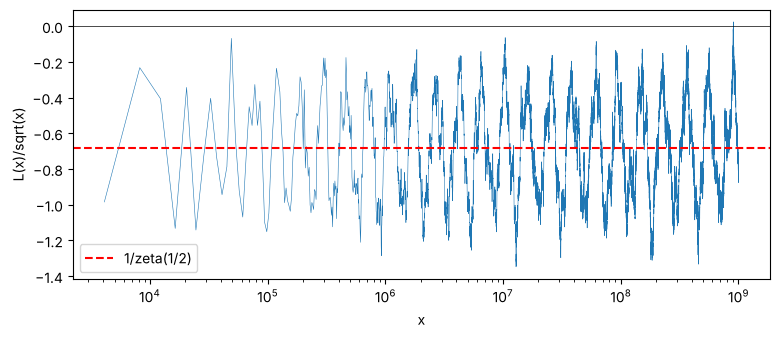

mean of L(x)/sqrt(x) over the samples with x > 10^6: -0.657;  1/zeta(1/2) = -0.6848


In [4]:
X = np.concatenate([s[0] for s in samples]); Y = np.concatenate([s[1] for s in samples])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.semilogx(X[X > 100], Y[X > 100] / np.sqrt(X[X > 100]), lw=0.4)
ax.axhline(1 / float(mp.zeta(0.5)), color='r', ls='--', label='1/zeta(1/2)')
ax.axhline(0, color='k', lw=0.5); ax.legend(); ax.set_xlabel('x'); ax.set_ylabel('L(x)/sqrt(x)')
plt.show()
print('mean of L(x)/sqrt(x) over the samples with x > 10^6: %.3f;  1/zeta(1/2) = %.4f'
      % (np.mean(Y[X > 1e6] / np.sqrt(X[X > 1e6])), 1 / float(mp.zeta(0.5))))

The first positive value is Tanaka's $906\,150\,257$, and the largest value below $10^9$ is $829$, inside the same stretch. The level of $L(x)/\sqrt x$ sits close to $1/\zeta(\frac12)\approx-0.685$ on average (the average over samples on a logarithmic scale fluctuates, since the oscillating terms are of the same size). Mertens' ratio $M(x)/\sqrt x$ stays well inside $(-1,1)$ up to $10^9$: the counterexamples of Odlyzko and te Riele are invisible at this scale.

### P1.4
**How to find it.** Store all sums $a^5+b^5$ with $a\le b$ in a dictionary, then for each $e$ and each pair $(c,d)$ look up $e^5-c^5-d^5$.

In [5]:
E = 150
fifth = [n**5 for n in range(E)]
pairs = {}
for a in range(1, E):
    for b in range(a, E):
        pairs.setdefault(fifth[a] + fifth[b], []).append((a, b))
sols = set()
for e in range(2, E):
    for c in range(1, e):
        for d in range(c, e):
            r = fifth[e] - fifth[c] - fifth[d]
            if r <= 0: break
            for a, b in pairs.get(r, []):
                if b <= c:
                    sols.add((a, b, c, d, e))
print(sorted(sols))
print(2682440**4 + 15365639**4 + 18796760**4 == 20615673**4, 95800**4 + 217519**4 + 414560**4 == 422481**4)

[(27, 84, 110, 133, 144)]
True True


The search returns exactly one solution, Lander and Parkin's $27^5+84^5+110^5+133^5=144^5$. Both fourth-power identities check out.

### P1.5
**How to find it.** `mpmath.quadosc` integrates oscillating functions given the frequency; the frequency of the product is the sum of the $a_k$. For the Monte Carlo, simulate $S=\sum a_kU_k$ directly.

In [6]:
mp.mp.dps = 25
for n in range(8):
    a = [mp.mpf(1) / (2 * k + 1) for k in range(n + 1)]
    f = lambda x: mp.fprod(mp.sinc(x * ak) for ak in a)
    v = mp.quadosc(f, [0, mp.inf], omega=sum(a))
    print(n, mp.nstr(v, 20), '  pi/2 - value = %.3e' % float(mp.pi / 2 - v))
a = [Fraction(1, 2 * k + 1) for k in range(1, 8)]
eps = sum(a) - 1
P1 = eps**7 / (math.factorial(7) * 2**7 * math.prod(a))
print('Corollary: deficit = pi * %.6e = %.6e' % (float(P1), math.pi * float(P1)))
a = np.array([1 / 2, 1 / 3, 1 / 4])
S = rng.uniform(-1, 1, size=(10**7, 3)) @ a
p = np.mean(np.abs(S) >= 1)
print('Monte Carlo P(|S| >= 1) = %.6f +- %.6f, exact 2/3456 = %.6f' % (p, 2 * math.sqrt(p / 1e7), 2 / 3456))

0 1.5707963267948966192   pi/2 - value = 0.000e+00


1 1.5707963267948966192   pi/2 - value = 0.000e+00


2 1.5707963267948966192   pi/2 - value = 2.585e-26


3 1.5707963267948966192   pi/2 - value = 0.000e+00


4 1.5707963267948966192   pi/2 - value = 2.585e-26


5 1.5707963267948966192   pi/2 - value = 5.065e-20


6 1.5707963267949014344   pi/2 - value = -4.815e-15


7 1.5707963267717961078   pi/2 - value = 2.310e-11
Corollary: deficit = pi * 7.353141e-12 = 2.310057e-11


Monte Carlo P(|S| >= 1) = 0.000573 +- 0.000015, exact 2/3456 = 0.000579


Seven integrals agree with $\frac\pi2$ to all the digits computed, and the eighth falls short by $2.31\times10^{-11}$, exactly the value of Corollary 1.5. For $a_k=\frac12,\frac13,\frac14$, the Monte Carlo estimate of $\mathbb P(|S|\ge1)$ matches $\frac2{3456}$, the value behind Exercise 1.12.